# DS605 Lab Assignment 7
## Image Representation, PCA, Eigenfaces and Face Recognition

**Course:** DS605 — Fundamentals of Machine Learning

### Objective
The objective of this project is to represent face images numerically, reduce their dimensionality using Principal Component Analysis (PCA), visualize eigenfaces, reconstruct images, perform face recognition in the reduced feature space, and compare the results with traditional machine-learning classifiers.

### Project Workflow
1. Load and inspect the grayscale face images.
2. Flatten the images into feature vectors and create the feature matrix.
3. Split the dataset into training and testing sets.
4. Implement PCA using NumPy eigendecomposition and Singular Value Decomposition (SVD).
5. Analyze explained variance and visualize eigenfaces.
6. Reconstruct images and evaluate compression.
7. Perform similarity-based face recognition.
8. Compare recognition performance using raw pixels and PCA features.
9. Train and evaluate traditional machine-learning classifiers.
10. Summarize the findings and prepare the project for GitHub.

**Reproducibility:** A fixed random seed will be used wherever randomness is involved.

**Implementation constraint:** PCA and eigenface calculations will be implemented using NumPy linear-algebra operations, without using scikit-learn's PCA implementation.

In [1]:
# ============================================================
# 1. IMPORTS AND PROJECT CONFIGURATION
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

# Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Display settings
np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (8, 5)

print("Imports completed successfully.")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

Imports completed successfully.
NumPy version: 2.3.3
Pandas version: 2.3.2


In [2]:
# ============================================================
# 2. INSPECT THE CURRENT WORKING DIRECTORY
# ============================================================

PROJECT_ROOT = Path.cwd()

print("Current working directory:")
print(PROJECT_ROOT)

print("\nFiles and folders in the current directory:")

for item in sorted(PROJECT_ROOT.iterdir()):
    print(f"{'[DIR] ' if item.is_dir() else '[FILE]'} {item.name}")

Current working directory:
c:\Users\pujit\Desktop\DAU\Sem 1\DS605 Fundamentals of Machine Learning\Lab\202618003_Pujita_Sunnapu_DS605\202618003_Lab7

Files and folders in the current directory:
[FILE] 202618003_Lab07.ipynb
[DIR]  data
[FILE] DS605_Lab7_Image_Representation_PCA_and_Face_Recognition_Assignment.pdf


## Part A — Image Representation

### A1. Dataset Inspection

Before processing the images, we inspect the dataset directory to identify its folder structure and image files. This helps us determine how subject labels can be extracted and how the images should be loaded.

In [3]:
# ============================================================
# 3. DATASET DIRECTORY INSPECTION
# ============================================================

DATASET_ROOT = PROJECT_ROOT / "data"

if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset directory not found: {DATASET_ROOT}"
    )

print("Dataset directory:", DATASET_ROOT)
print("\nTop-level contents:")

for item in sorted(DATASET_ROOT.iterdir()):
    print(f"{'[DIR] ' if item.is_dir() else '[FILE]'} {item.name}")

# Count files by extension recursively
all_dataset_files = [
    file_path
    for file_path in DATASET_ROOT.rglob("*")
    if file_path.is_file()
]

extension_counts = {}

for file_path in all_dataset_files:
    extension = file_path.suffix.lower() or "[no extension]"
    extension_counts[extension] = extension_counts.get(extension, 0) + 1

print("\nTotal files:", len(all_dataset_files))
print("\nFile counts by extension:")

for extension, count in sorted(extension_counts.items()):
    print(f"{extension}: {count}")

print("\nFirst 15 file paths:")

for file_path in all_dataset_files[:15]:
    print(file_path.relative_to(DATASET_ROOT))

Dataset directory: c:\Users\pujit\Desktop\DAU\Sem 1\DS605 Fundamentals of Machine Learning\Lab\202618003_Pujita_Sunnapu_DS605\202618003_Lab7\data

Top-level contents:
[DIR]  archive
[FILE] archive.zip

Total files: 402

File counts by extension:
.pgm: 400
.zip: 1
[no extension]: 1

First 15 file paths:
archive.zip
archive\README
archive\s1\1.pgm
archive\s1\10.pgm
archive\s1\2.pgm
archive\s1\3.pgm
archive\s1\4.pgm
archive\s1\5.pgm
archive\s1\6.pgm
archive\s1\7.pgm
archive\s1\8.pgm
archive\s1\9.pgm
archive\s10\1.pgm
archive\s10\10.pgm
archive\s10\2.pgm


### A2. Loading and Inspecting Images

The ORL dataset contains grayscale face images stored in PGM format. Each image will be loaded as a two-dimensional NumPy array, where each element represents a pixel intensity.

We will extract the subject label from the parent folder name and the image number from the filename. Before proceeding, we will verify that the images have consistent dimensions and inspect their intensity values.

In [4]:
# ============================================================
# 4. LOAD ORL FACE IMAGES
# ============================================================

IMAGE_DATA_DIR = DATASET_ROOT / "archive"

if not IMAGE_DATA_DIR.exists():
    raise FileNotFoundError(
        f"Image directory not found: {IMAGE_DATA_DIR}"
    )

# Collect PGM image files
orl_image_paths = list(IMAGE_DATA_DIR.rglob("*.pgm"))

# Sort numerically by subject and image number
orl_image_paths = sorted(
    orl_image_paths,
    key=lambda path: (
        int(path.parent.name[1:]),
        int(path.stem)
    )
)

orl_image_arrays = []
orl_subject_labels = []
orl_image_filenames = []

for image_path in orl_image_paths:
    with Image.open(image_path) as image_file:
        grayscale_image = np.asarray(
            image_file.convert("L"),
            dtype=np.uint8
        )

    orl_image_arrays.append(grayscale_image)
    orl_subject_labels.append(image_path.parent.name)
    orl_image_filenames.append(image_path.name)

print("Number of images loaded:", len(orl_image_arrays))
print("Number of labels:", len(orl_subject_labels))
print("Number of unique subjects:", len(set(orl_subject_labels)))

Number of images loaded: 400
Number of labels: 400
Number of unique subjects: 40


In [5]:
# ============================================================
# 5. VALIDATE DATASET STRUCTURE
# ============================================================

orl_image_shapes = [
    image_array.shape for image_array in orl_image_arrays
]

orl_unique_shapes = sorted(set(orl_image_shapes))

print("Unique image dimensions:", orl_unique_shapes)

print("\nFirst image:")
print("Shape:", orl_image_arrays[0].shape)
print("Data type:", orl_image_arrays[0].dtype)
print("Minimum intensity:", orl_image_arrays[0].min())
print("Maximum intensity:", orl_image_arrays[0].max())
print("Mean intensity:", round(orl_image_arrays[0].mean(), 2))

# Count images per subject
orl_subject_counts = (
    pd.Series(orl_subject_labels, name="subject")
    .value_counts()
    .sort_index()
    .rename_axis("subject")
    .reset_index(name="image_count")
)

display(orl_subject_counts)

# Validate assumptions before further processing
assert len(orl_image_arrays) > 0, "No images were loaded."
assert len(orl_image_arrays) == len(orl_subject_labels)
assert len(orl_unique_shapes) == 1, (
    "Images have inconsistent dimensions; preprocessing is required."
)

print("\nDataset validation completed.")

Unique image dimensions: [(112, 92)]

First image:
Shape: (112, 92)
Data type: uint8
Minimum intensity: 11
Maximum intensity: 234
Mean intensity: 128.34


,subject,image_count
0,s1,10
1,s10,10
2,s11,10
3,s12,10
4,s13,10
5,s14,10
6,s15,10
7,s16,10
8,s17,10
9,s18,10



Dataset validation completed.


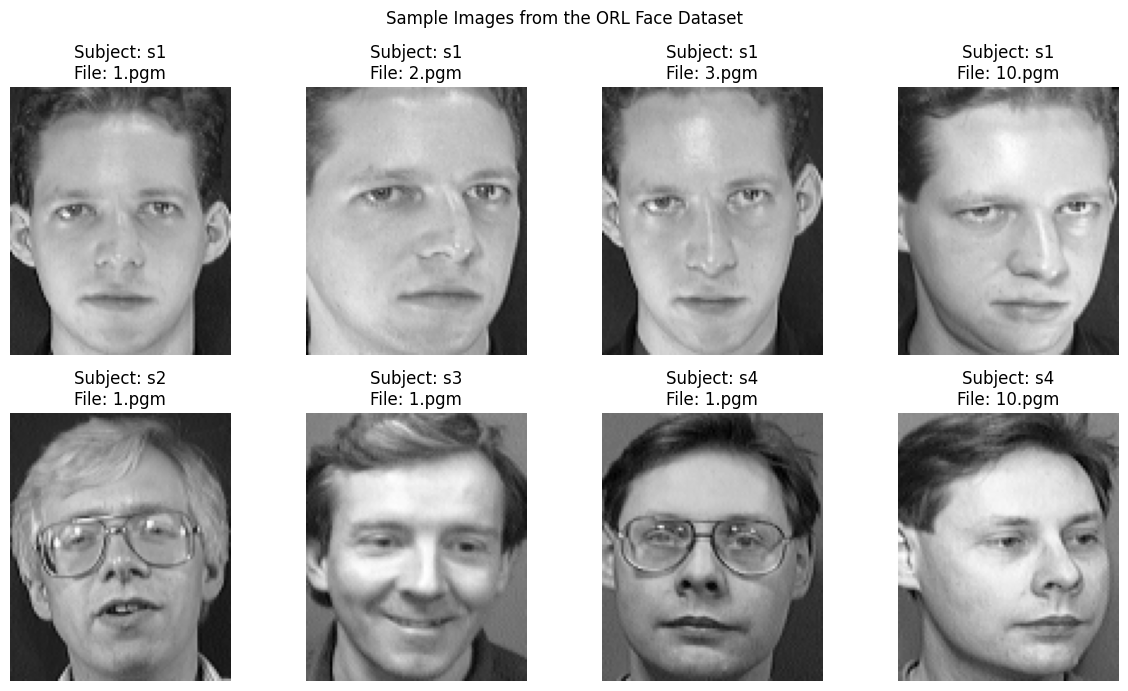

In [6]:
# ============================================================
# 6. VISUALIZE SAMPLE FACE IMAGES
# ============================================================

orl_sample_indices = [0, 1, 2, 9, 10, 20, 30, 39]

fig, axes = plt.subplots(2, 4, figsize=(12, 7))

for axis, image_index in zip(axes.flat, orl_sample_indices):
    axis.imshow(orl_image_arrays[image_index], cmap="gray")
    axis.set_title(
        f"Subject: {orl_subject_labels[image_index]}\n"
        f"File: {orl_image_filenames[image_index]}"
    )
    axis.axis("off")

plt.suptitle("Sample Images from the ORL Face Dataset")
plt.tight_layout()
plt.show()

### A3. Flattening Images into Feature Vectors

A grayscale image is represented as a two-dimensional pixel matrix. Machine-learning algorithms require a numerical feature representation, so each image is flattened into a one-dimensional vector.

For an image of height \(H=112\) and width \(W=92\), the feature vector contains \(H \times W = 10{,}304\) pixel values.

Stacking the feature vectors produces the complete image matrix \(X\), where each row corresponds to an image and each column corresponds to a pixel position. A separate label vector stores the identity of the subject associated with each image.

In [7]:
# ============================================================
# 7. CREATE THE COMPLETE IMAGE FEATURE MATRIX
# ============================================================

orl_image_height, orl_image_width = orl_image_arrays[0].shape
orl_num_pixels = orl_image_height * orl_image_width

# Flatten each image and stack the vectors row-wise
orl_image_matrix = np.stack(
    [image_array.reshape(-1) for image_array in orl_image_arrays],
    axis=0
)

# Store labels and filenames as NumPy arrays
orl_labels_array = np.asarray(orl_subject_labels)
orl_filenames_array = np.asarray(orl_image_filenames)

print("Image matrix shape:", orl_image_matrix.shape)
print("Labels array shape:", orl_labels_array.shape)
print("Number of pixel features:", orl_num_pixels)
print("Image matrix data type:", orl_image_matrix.dtype)

print("\nFirst 10 pixel values of the first image:")
print(orl_image_matrix[0, :10])

# Verify dimensions and alignment
assert orl_image_matrix.shape == (400, 10304)
assert len(orl_labels_array) == orl_image_matrix.shape[0]
assert len(orl_filenames_array) == orl_image_matrix.shape[0]

print("\nFeature matrix validation successful.")

Image matrix shape: (400, 10304)
Labels array shape: (400,)
Number of pixel features: 10304
Image matrix data type: uint8

First 10 pixel values of the first image:
[48 49 45 47 49 57 39 42 53 49]

Feature matrix validation successful.


### A4. Creating a Reproducible Train-Test Split

We will divide the dataset into training and testing sets while ensuring that every subject is represented in both sets.

For each subject, seven images will be randomly assigned to training and the remaining three to testing. This gives a 70:30 split within every subject, with a fixed random seed for reproducibility.

We will implement the split using NumPy rather than scikit-learn, preserving the assignment's restriction on scikit-learn usage for the final traditional machine-learning comparison.

In [8]:
# ============================================================
# 8. STRATIFIED TRAIN-TEST SPLIT USING NUMPY
# ============================================================

orl_split_rng = np.random.default_rng(RANDOM_SEED)

orl_unique_subjects = sorted(
    set(orl_labels_array),
    key=lambda subject_label: int(subject_label[1:])
)

orl_train_indices = []
orl_test_indices = []

for subject_label in orl_unique_subjects:
    # Find all indices belonging to the current subject
    subject_image_indices = np.flatnonzero(
        orl_labels_array == subject_label
    )

    # Randomly shuffle this subject's image indices
    shuffled_subject_indices = orl_split_rng.permutation(
        subject_image_indices
    )

    # Use 7 images for training and 3 for testing
    orl_train_indices.extend(shuffled_subject_indices[:7])
    orl_test_indices.extend(shuffled_subject_indices[7:])

# Convert index lists to arrays
orl_train_indices = np.asarray(orl_train_indices, dtype=int)
orl_test_indices = np.asarray(orl_test_indices, dtype=int)

# Shuffle the combined training and testing indices independently
orl_train_indices = orl_split_rng.permutation(orl_train_indices)
orl_test_indices = orl_split_rng.permutation(orl_test_indices)

# Create training and testing datasets
orl_X_train_raw = orl_image_matrix[orl_train_indices].astype(np.float64)
orl_X_test_raw = orl_image_matrix[orl_test_indices].astype(np.float64)

orl_y_train = orl_labels_array[orl_train_indices]
orl_y_test = orl_labels_array[orl_test_indices]

print("Training feature matrix:", orl_X_train_raw.shape)
print("Testing feature matrix:", orl_X_test_raw.shape)
print("Training labels:", orl_y_train.shape)
print("Testing labels:", orl_y_test.shape)

print("\nImages per subject in training:")
print(pd.Series(orl_y_train).value_counts().sort_index().to_dict())

print("\nImages per subject in testing:")
print(pd.Series(orl_y_test).value_counts().sort_index().to_dict())

# Verify the split
assert len(orl_train_indices) == 280
assert len(orl_test_indices) == 120
assert set(orl_y_train) == set(orl_y_test) == set(orl_unique_subjects)
assert len(set(orl_train_indices) & set(orl_test_indices)) == 0

print("\nTrain-test split validation successful.")

Training feature matrix: (280, 10304)
Testing feature matrix: (120, 10304)
Training labels: (280,)
Testing labels: (120,)

Images per subject in training:
{'s1': 7, 's10': 7, 's11': 7, 's12': 7, 's13': 7, 's14': 7, 's15': 7, 's16': 7, 's17': 7, 's18': 7, 's19': 7, 's2': 7, 's20': 7, 's21': 7, 's22': 7, 's23': 7, 's24': 7, 's25': 7, 's26': 7, 's27': 7, 's28': 7, 's29': 7, 's3': 7, 's30': 7, 's31': 7, 's32': 7, 's33': 7, 's34': 7, 's35': 7, 's36': 7, 's37': 7, 's38': 7, 's39': 7, 's4': 7, 's40': 7, 's5': 7, 's6': 7, 's7': 7, 's8': 7, 's9': 7}

Images per subject in testing:
{'s1': 3, 's10': 3, 's11': 3, 's12': 3, 's13': 3, 's14': 3, 's15': 3, 's16': 3, 's17': 3, 's18': 3, 's19': 3, 's2': 3, 's20': 3, 's21': 3, 's22': 3, 's23': 3, 's24': 3, 's25': 3, 's26': 3, 's27': 3, 's28': 3, 's29': 3, 's3': 3, 's30': 3, 's31': 3, 's32': 3, 's33': 3, 's34': 3, 's35': 3, 's36': 3, 's37': 3, 's38': 3, 's39': 3, 's4': 3, 's40': 3, 's5': 3, 's6': 3, 's7': 3, 's8': 3, 's9': 3}

Train-test split validation 

In [9]:
# ============================================================
# 9. VERIFY SUBJECT COVERAGE AND SPLIT INTEGRITY
# ============================================================

orl_split_summary = pd.DataFrame({
    "subject": orl_unique_subjects,
    "training_images": [
        np.sum(orl_y_train == subject_label)
        for subject_label in orl_unique_subjects
    ],
    "testing_images": [
        np.sum(orl_y_test == subject_label)
        for subject_label in orl_unique_subjects
    ]
})

display(orl_split_summary.head(10))

print("Subjects represented in training:", len(set(orl_y_train)))
print("Subjects represented in testing:", len(set(orl_y_test)))
print("Total training images:", len(orl_y_train))
print("Total testing images:", len(orl_y_test))

assert (orl_split_summary["training_images"] == 7).all()
assert (orl_split_summary["testing_images"] == 3).all()

print("\nAll subjects have the expected number of images in each split.")

,subject,training_images,testing_images
0,s1,7,3
1,s2,7,3
2,s3,7,3
3,s4,7,3
4,s5,7,3
5,s6,7,3
6,s7,7,3
7,s8,7,3
8,s9,7,3
9,s10,7,3


Subjects represented in training: 40
Subjects represented in testing: 40
Total training images: 280
Total testing images: 120

All subjects have the expected number of images in each split.


## Part B — PCA, Eigenfaces and Compression

### B1. Mean Face and Mean Centering

Principal Component Analysis (PCA) transforms high-dimensional data into a lower-dimensional representation while preserving as much variance as possible.

The mean face is calculated by averaging the training images pixel by pixel. Each training image is then centered by subtracting this mean face.

For the training matrix \(X_{\text{train}}\), containing \(n\) images and \(p\) pixel features, the mean face is

\[
\boldsymbol{\mu}=\frac{1}{n}\sum_{i=1}^{n}\mathbf{x}_i.
\]

The centered training matrix is

\[
X_c=X_{\text{train}}-\boldsymbol{\mu}.
\]

Centering is essential because PCA identifies directions of maximum variance relative to the mean of the training data. The mean face will also serve as the reference when reconstructing images.

Mean face vector shape: (10304,)
Centered training matrix: (280, 10304)
Centered testing matrix: (120, 10304)
Maximum absolute mean of centered training features: 3.5425630682896424e-14


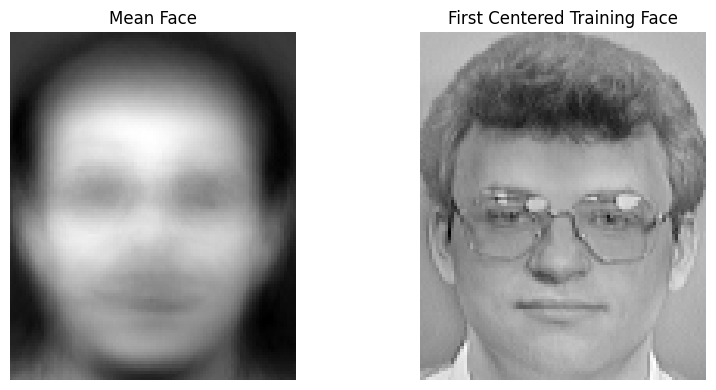

In [10]:
# ============================================================
# 10. COMPUTE THE MEAN FACE AND CENTER THE TRAINING DATA
# ============================================================

orl_mean_face_vector = np.mean(orl_X_train_raw, axis=0)

orl_X_train_centered = (
    orl_X_train_raw - orl_mean_face_vector
)

# Center test images using the TRAINING mean only
orl_X_test_centered = (
    orl_X_test_raw - orl_mean_face_vector
)

# Reshape the mean vector back into an image
orl_mean_face_image = orl_mean_face_vector.reshape(
    orl_image_height,
    orl_image_width
)

print("Mean face vector shape:", orl_mean_face_vector.shape)
print("Centered training matrix:", orl_X_train_centered.shape)
print("Centered testing matrix:", orl_X_test_centered.shape)
print(
    "Maximum absolute mean of centered training features:",
    np.max(np.abs(np.mean(orl_X_train_centered, axis=0)))
)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(orl_mean_face_image, cmap="gray")
axes[0].set_title("Mean Face")
axes[0].axis("off")

axes[1].imshow(
    orl_X_train_centered[0].reshape(
        orl_image_height, orl_image_width
    ),
    cmap="gray"
)
axes[1].set_title("First Centered Training Face")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### B2. Covariance-Based PCA Using NumPy Eigendecomposition

The covariance matrix describes how pixel features vary together. In conventional PCA, it is computed as

\[
C=\frac{1}{n-1}X_c^\top X_c.
\]

The eigenvectors of \(C\) represent principal directions, and the corresponding eigenvalues indicate the variance captured by those directions.

However, \(C\) would have dimensions \(10{,}304 \times 10{,}304\). Instead, we use the smaller Gram matrix

\[
G=\frac{1}{n-1}X_cX_c^\top.
\]

We eigendecompose \(G\) and recover the principal directions in pixel space using

\[
\mathbf{v}_j=
\frac{X_c^\top\mathbf{u}_j}
{\sqrt{(n-1)\lambda_j}},
\]

where \(\lambda_j\) and \(\mathbf{u}_j\) are the corresponding eigenvalue and eigenvector of \(G\).

This approach avoids constructing the much larger covariance matrix while recovering the same nonzero principal directions, up to numerical precision and sign.

In [11]:
# ============================================================
# 11. PCA USING THE GRAM MATRIX AND EIGENDECOMPOSITION
# ============================================================

orl_num_train_samples = orl_X_train_centered.shape[0]

# Construct the smaller Gram matrix
orl_gram_matrix = (
    orl_X_train_centered @ orl_X_train_centered.T
) / (orl_num_train_samples - 1)

# Eigenvalues and eigenvectors of the Gram matrix
orl_gram_eigenvalues, orl_gram_eigenvectors = np.linalg.eigh(
    orl_gram_matrix
)

# Sort eigenvalues in descending order
orl_eigen_order = np.argsort(orl_gram_eigenvalues)[::-1]

orl_gram_eigenvalues = orl_gram_eigenvalues[orl_eigen_order]
orl_gram_eigenvectors = orl_gram_eigenvectors[:, orl_eigen_order]

# Remove tiny numerical eigenvalues and negative round-off values
orl_eigenvalue_tolerance = (
    np.finfo(float).eps
    * max(orl_gram_matrix.shape)
    * max(abs(orl_gram_eigenvalues[0]), 1.0)
)

orl_valid_eigen_mask = (
    orl_gram_eigenvalues > orl_eigenvalue_tolerance
)

orl_valid_eigenvalues = orl_gram_eigenvalues[orl_valid_eigen_mask]
orl_valid_gram_vectors = orl_gram_eigenvectors[:, orl_valid_eigen_mask]

# Recover principal directions in the original pixel space
orl_eigenface_components = (
    orl_X_train_centered.T @ orl_valid_gram_vectors
) / np.sqrt(
    (orl_num_train_samples - 1) * orl_valid_eigenvalues
)

print("Gram matrix shape:", orl_gram_matrix.shape)
print("Number of positive eigenvalues:", len(orl_valid_eigenvalues))
print("Principal directions shape:", orl_eigenface_components.shape)

# Check orthonormality of the recovered principal directions
orl_eigenface_orthogonality = (
    orl_eigenface_components.T @ orl_eigenface_components
)

orl_identity_matrix = np.eye(orl_eigenface_components.shape[1])

print(
    "Maximum orthonormality error:",
    np.max(np.abs(orl_eigenface_orthogonality - orl_identity_matrix))
)

Gram matrix shape: (280, 280)
Number of positive eigenvalues: 279
Principal directions shape: (10304, 279)
Maximum orthonormality error: 1.035838081975271e-13


### B3. PCA Using Singular Value Decomposition

Singular Value Decomposition (SVD) factorizes the centered training matrix as

\[
X_c=U\Sigma V^\top.
\]

The columns of \(V\) are the principal directions in pixel space. The eigenvalues of the sample covariance matrix are obtained from the squared singular values:

\[
\lambda_j=\frac{\sigma_j^2}{n-1}.
\]

We will compute SVD independently and compare its principal directions and eigenvalues with the eigendecomposition-based approach. Since eigenvectors can differ by a sign without changing their meaning, the comparison will use the absolute dot products between corresponding components.

In [12]:
# ============================================================
# 12. PCA USING NUMPY SVD
# ============================================================

orl_svd_U, orl_svd_singular_values, orl_svd_Vt = np.linalg.svd(
    orl_X_train_centered,
    full_matrices=False
)

# Principal directions are columns of V
orl_svd_components = orl_svd_Vt.T

# Eigenvalues of the sample covariance matrix
orl_svd_eigenvalues = (
    orl_svd_singular_values ** 2
) / (orl_num_train_samples - 1)

print("SVD U shape:", orl_svd_U.shape)
print("Singular values shape:", orl_svd_singular_values.shape)
print("SVD principal directions shape:", orl_svd_components.shape)
print("SVD eigenvalues shape:", orl_svd_eigenvalues.shape)

SVD U shape: (280, 280)
Singular values shape: (280,)
SVD principal directions shape: (10304, 280)
SVD eigenvalues shape: (280,)


In [13]:
# ============================================================
# 13. COMPARE EIGENDECOMPOSITION AND SVD
# ============================================================

orl_common_component_count = min(
    len(orl_valid_eigenvalues),
    len(orl_svd_eigenvalues)
)

# Compare the eigenvalues
orl_eigenvalue_comparison = pd.DataFrame({
    "Component": np.arange(1, orl_common_component_count + 1),
    "Gram_Eigenvalue": orl_valid_eigenvalues[
        :orl_common_component_count
    ],
    "SVD_Eigenvalue": orl_svd_eigenvalues[
        :orl_common_component_count
    ]
})

orl_eigenvalue_comparison["Absolute_Difference"] = np.abs(
    orl_eigenvalue_comparison["Gram_Eigenvalue"]
    - orl_eigenvalue_comparison["SVD_Eigenvalue"]
)

display(orl_eigenvalue_comparison.head(10))

# Compare the directions using absolute dot products
orl_component_alignment = np.abs(
    np.sum(
        orl_eigenface_components[:, :orl_common_component_count]
        * orl_svd_components[:, :orl_common_component_count],
        axis=0
    )
)

print(
    "\nMean absolute alignment of corresponding components:",
    np.mean(orl_component_alignment)
)

print(
    "Minimum absolute alignment among first 10 components:",
    np.min(orl_component_alignment[:10])
)

print(
    "Maximum eigenvalue difference:",
    orl_eigenvalue_comparison["Absolute_Difference"].max()
)

,Component,Gram_Eigenvalue,SVD_Eigenvalue,Absolute_Difference
0,1,2.846099e+06,2.846099e+06,3.725290e-09
1,2,2.016980e+06,2.016980e+06,2.561137e-09
2,3,1.133662e+06,1.133662e+06,2.328306e-10
3,4,9.170976e+05,9.170976e+05,4.656613e-10
4,5,8.145132e+05,8.145132e+05,1.280569e-09
5,6,5.229294e+05,5.229294e+05,1.629815e-09
6,7,4.219391e+05,4.219391e+05,2.328306e-10
7,8,3.712002e+05,3.712002e+05,1.338776e-09
8,9,3.218318e+05,3.218318e+05,5.820766e-11
9,10,2.921422e+05,2.921422e+05,5.820766e-11



Mean absolute alignment of corresponding components: 1.0
Minimum absolute alignment among first 10 components: 0.9999999999999976
Maximum eigenvalue difference: 3.725290298461914e-09


### B4. Explained Variance and Selecting Principal Components

Each principal component captures a proportion of the total variance in the training data. The explained variance ratio for component \(j\) is

\[
r_j=\frac{\lambda_j}{\sum_{k=1}^{m}\lambda_k}.
\]

The cumulative explained variance ratio after retaining \(k\) components is

\[
R_k=\sum_{j=1}^{k}r_j.
\]

We will plot the cumulative explained variance and identify the minimum number of principal components required to retain at least 90% of the training variance. Only the training data will be used to determine this threshold, avoiding information leakage from the test set.

Minimum components for 90% variance: 92
Cumulative variance at selected component count: 0.900366
Variance retained by the first 10 components: 0.602592


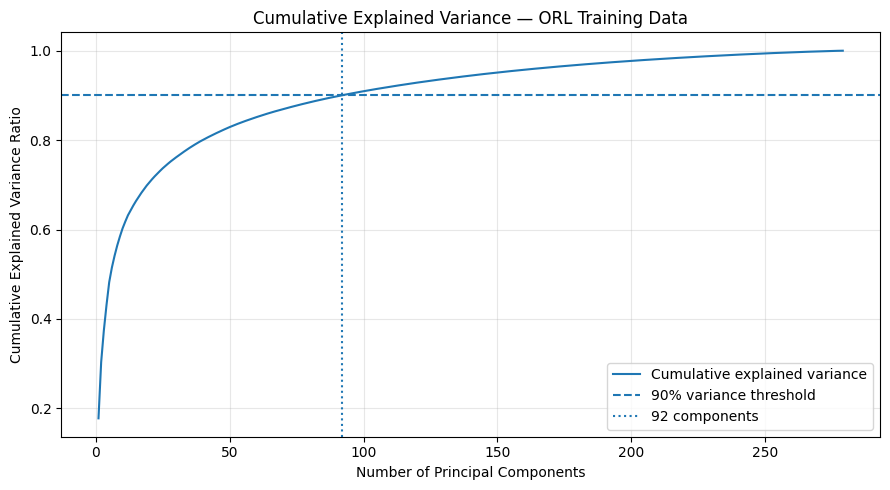

In [14]:
# ============================================================
# 14. EXPLAINED VARIANCE AND 90% COMPONENT THRESHOLD
# ============================================================

orl_explained_variance_ratio = (
    orl_valid_eigenvalues / np.sum(orl_valid_eigenvalues)
)

orl_cumulative_explained_variance = np.cumsum(
    orl_explained_variance_ratio
)

orl_variance_threshold = 0.90

orl_components_for_90_variance = (
    np.searchsorted(
        orl_cumulative_explained_variance,
        orl_variance_threshold
    ) + 1
)

print(
    "Minimum components for 90% variance:",
    orl_components_for_90_variance
)

print(
    "Cumulative variance at selected component count:",
    round(
        orl_cumulative_explained_variance[
            orl_components_for_90_variance - 1
        ],
        6
    )
)

print(
    "Variance retained by the first 10 components:",
    round(np.sum(orl_explained_variance_ratio[:10]), 6)
)

# Plot cumulative explained variance
plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, len(orl_cumulative_explained_variance) + 1),
    orl_cumulative_explained_variance,
    label="Cumulative explained variance"
)

plt.axhline(
    y=orl_variance_threshold,
    linestyle="--",
    label="90% variance threshold"
)

plt.axvline(
    x=orl_components_for_90_variance,
    linestyle=":",
    label=f"{orl_components_for_90_variance} components"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.title("Cumulative Explained Variance — ORL Training Data")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# 15. INDIVIDUAL AND CUMULATIVE EXPLAINED VARIANCE
# ============================================================

orl_variance_table = pd.DataFrame({
    "Component": np.arange(
        1, len(orl_valid_eigenvalues) + 1
    ),
    "Eigenvalue": orl_valid_eigenvalues,
    "Explained_Variance_Ratio": orl_explained_variance_ratio,
    "Cumulative_Explained_Variance": (
        orl_cumulative_explained_variance
    )
})

display(orl_variance_table.head(15))

print("\nVariance at selected component count:")
print(
    orl_variance_table.iloc[
        orl_components_for_90_variance - 1
    ]
)

,Component,Eigenvalue,Explained_Variance_Ratio,Cumulative_Explained_Variance
0,1,2.846099e+06,0.177569,0.177569
1,2,2.016980e+06,0.125840,0.303410
2,3,1.133662e+06,0.070730,0.374140
3,4,9.170976e+05,0.057218,0.431358
4,5,8.145132e+05,0.050818,0.482176
5,6,5.229294e+05,0.032626,0.514801
6,7,4.219391e+05,0.026325,0.541126
7,8,3.712002e+05,0.023159,0.564286
8,9,3.218318e+05,0.020079,0.584365
9,10,2.921422e+05,0.018227,0.602592



Variance at selected component count:
Component                           92.000000
Eigenvalue                       19178.925372
Explained_Variance_Ratio             0.001197
Cumulative_Explained_Variance        0.900366
Name: 91, dtype: float64


### B5. Visualizing Eigenfaces

Eigenfaces are the principal directions reshaped into the original image dimensions. They represent patterns of pixel variation across the training faces rather than individual people's faces.

The first eigenface captures the direction of greatest variance, while subsequent eigenfaces capture progressively smaller amounts of variance subject to orthogonality.

We will visualize the first several eigenfaces using the principal directions obtained through covariance-based eigendecomposition. Positive and negative pixel values are both meaningful because each eigenface represents a direction of variation around the mean face.

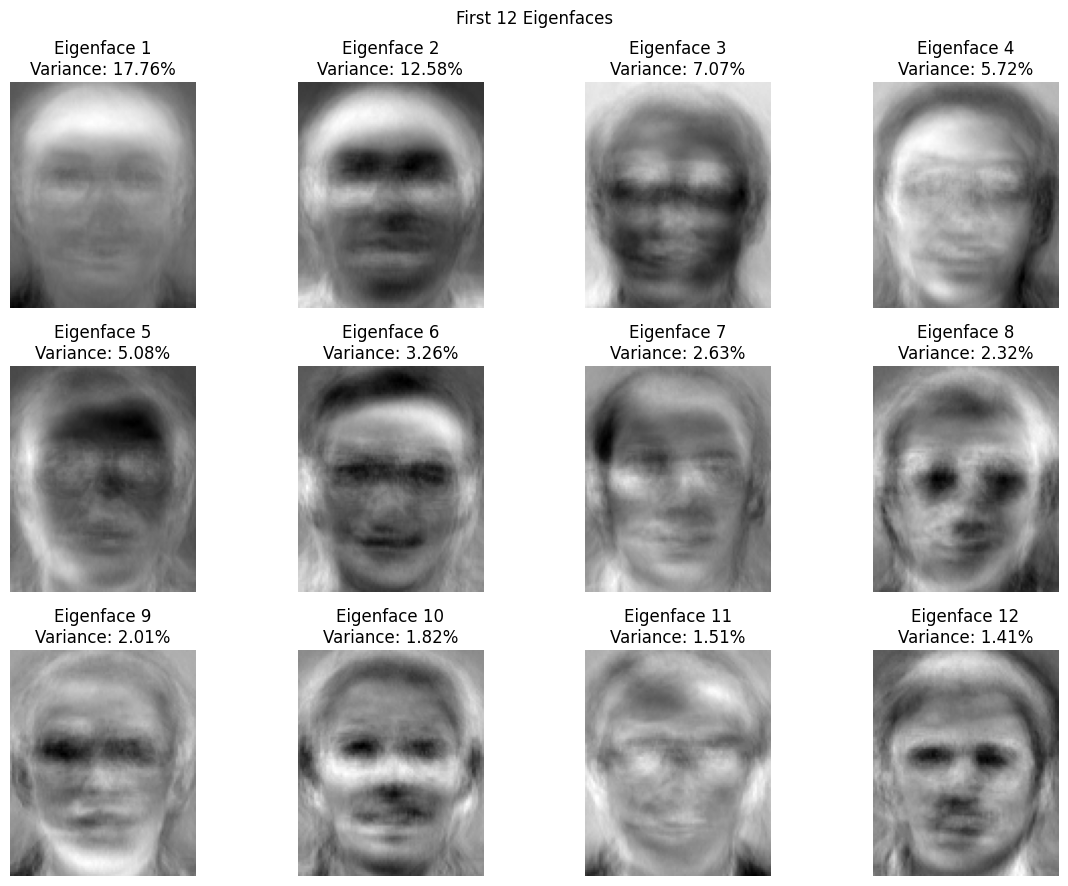

In [16]:
# ============================================================
# 16. VISUALIZE THE FIRST 12 EIGENFACES
# ============================================================

orl_num_eigenfaces_to_display = 12

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for eigenface_index, axis in enumerate(axes.flat):
    eigenface_image = orl_eigenface_components[
        :, eigenface_index
    ].reshape(orl_image_height, orl_image_width)

    axis.imshow(eigenface_image, cmap="gray")
    axis.set_title(
        f"Eigenface {eigenface_index + 1}\n"
        f"Variance: "
        f"{orl_explained_variance_ratio[eigenface_index]:.2%}"
    )
    axis.axis("off")

plt.suptitle("First 12 Eigenfaces")
plt.tight_layout()
plt.show()

### B6. Projecting Faces into PCA Space

After selecting the number of components needed to retain at least 90% of the variance, we project the centered images onto the selected principal directions.

If \(V_k\) contains the first \(k\) principal directions, the reduced representation is

\[
Z_{\text{train}}=X_{c,\text{train}}V_k
\]

and

\[
Z_{\text{test}}=X_{c,\text{test}}V_k.
\]

Each face is now represented by \(k\) numerical coefficients instead of 10,304 raw pixel values. The same training-derived mean face and principal directions are applied to the test set.

In [17]:
# ============================================================
# 17. PROJECT TRAINING AND TESTING IMAGES INTO PCA SPACE
# ============================================================

orl_selected_components = orl_eigenface_components[
    :, :orl_components_for_90_variance
]

orl_X_train_pca = (
    orl_X_train_centered @ orl_selected_components
)

orl_X_test_pca = (
    orl_X_test_centered @ orl_selected_components
)

print("Selected components:", orl_components_for_90_variance)
print("Selected component matrix:", orl_selected_components.shape)
print("Reduced training representation:", orl_X_train_pca.shape)
print("Reduced testing representation:", orl_X_test_pca.shape)

assert orl_X_train_pca.shape == (
    len(orl_y_train),
    orl_components_for_90_variance
)

assert orl_X_test_pca.shape == (
    len(orl_y_test),
    orl_components_for_90_variance
)

print("\nPCA projection completed successfully.")

Selected components: 92
Selected component matrix: (10304, 92)
Reduced training representation: (280, 92)
Reduced testing representation: (120, 92)

PCA projection completed successfully.


### B7. Face Reconstruction from PCA Features

PCA represents an image using a mean face and a weighted combination of selected principal directions. We can reconstruct an approximation of an image using

\[
\hat{\mathbf{x}}=\boldsymbol{\mu}+\mathbf{z}V_k^\top,
\]

where \(\boldsymbol{\mu}\) is the training mean face, \(\mathbf{z}\) is the reduced representation, and \(V_k\) contains the selected principal directions.

The reconstruction is generally not identical to the original because the discarded components contain some information. We will compare original and reconstructed test images and calculate the mean squared error (MSE) across the test set.

\[
\operatorname{MSE}=\frac{1}{Np}\sum_{i=1}^{N}\sum_{j=1}^{p}(x_{ij}-\hat{x}_{ij})^2.
\]

A lower MSE indicates a more accurate reconstruction.

In [19]:
# ============================================================
# 18. RECONSTRUCT TEST IMAGES FROM PCA REPRESENTATIONS
# ============================================================

orl_X_test_reconstructed = (
    orl_X_test_pca @ orl_selected_components.T
    + orl_mean_face_vector
)

print("Original test matrix:", orl_X_test_raw.shape)
print("Reconstructed test matrix:", orl_X_test_reconstructed.shape)

# Calculate reconstruction errors using floating-point values
orl_test_reconstruction_errors = (
    orl_X_test_raw - orl_X_test_reconstructed
)

orl_test_reconstruction_mse = np.mean(
    orl_test_reconstruction_errors ** 2
)

orl_test_reconstruction_rmse = np.sqrt(
    orl_test_reconstruction_mse
)

orl_test_reconstruction_mae = np.mean(
    np.abs(orl_test_reconstruction_errors)
)

print(f"Test reconstruction MSE: {orl_test_reconstruction_mse:.4f}")
print(f"Test reconstruction RMSE: {orl_test_reconstruction_rmse:.4f}")

print(f"Test reconstruction MAE: {orl_test_reconstruction_mae:.4f}")

Original test matrix: (120, 10304)
Reconstructed test matrix: (120, 10304)
Test reconstruction MSE: 335.5241
Test reconstruction RMSE: 18.3173
Test reconstruction MAE: 13.0618


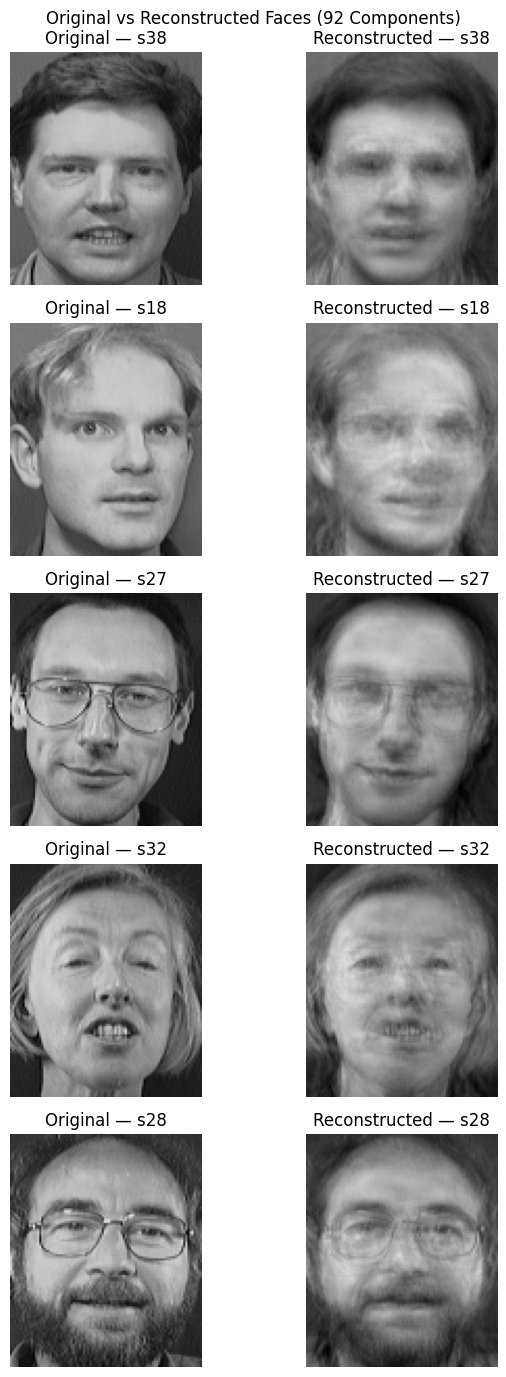

In [20]:
# ============================================================
# 19. VISUALIZE ORIGINAL AND RECONSTRUCTED TEST FACES
# ============================================================

orl_reconstruction_sample_indices = [0, 10, 20, 30, 40]

fig, axes = plt.subplots(
    len(orl_reconstruction_sample_indices),
    2,
    figsize=(7, 14)
)

for row_index, test_index in enumerate(
    orl_reconstruction_sample_indices
):
    orl_original_face = orl_X_test_raw[test_index].reshape(
        orl_image_height, orl_image_width
    )

    orl_reconstructed_face = orl_X_test_reconstructed[
        test_index
    ].reshape(orl_image_height, orl_image_width)

    axes[row_index, 0].imshow(
        orl_original_face, cmap="gray", vmin=0, vmax=255
    )
    axes[row_index, 0].set_title(
        f"Original — {orl_y_test[test_index]}"
    )
    axes[row_index, 0].axis("off")

    axes[row_index, 1].imshow(
        orl_reconstructed_face,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[row_index, 1].set_title(
        f"Reconstructed — {orl_y_test[test_index]}"
    )
    axes[row_index, 1].axis("off")

plt.suptitle(
    f"Original vs Reconstructed Faces ({orl_components_for_90_variance} Components)"
)
plt.tight_layout()

plt.show()

### B8. Storage Comparison

The original image representation stores 10,304 pixel values per image. The PCA representation stores 92 coefficients per image, in addition to the mean face and selected principal directions required for reconstruction.

We will compare the per-image storage requirements using the actual NumPy data types. This comparison measures the representation size and does not include image-file encoding, filenames, labels, or the one-time cost of storing the PCA model.


For a fairer assessment of practical compression, we will also calculate the amortized storage cost when the PCA model is shared across all images.

In [21]:
# ============================================================
# 20. COMPARE ORIGINAL AND PCA STORAGE REQUIREMENTS
# ============================================================

orl_original_bytes_per_image = (
    orl_image_matrix.shape[1] * orl_image_matrix.dtype.itemsize
)

orl_pca_bytes_per_image = (
    orl_X_train_pca.shape[1] * orl_X_train_pca.dtype.itemsize
)

orl_original_dataset_bytes = orl_image_matrix.nbytes

orl_all_pca_features = np.vstack([
    orl_X_train_pca,
    orl_X_test_pca
])

orl_pca_features_dataset_bytes = orl_all_pca_features.nbytes

# One shared PCA model: mean vector and selected components
orl_pca_model_bytes = (
    orl_mean_face_vector.nbytes
    + orl_selected_components.nbytes
)

orl_total_pca_bytes = (
    orl_pca_features_dataset_bytes
    + orl_pca_model_bytes
)

orl_storage_summary = pd.DataFrame({
    "Representation": [
        "Original pixel matrix",
        "PCA coefficients only",
        "PCA coefficients + shared PCA model"
    ],
    "Total_bytes": [
        orl_original_dataset_bytes,
        orl_pca_features_dataset_bytes,
        orl_total_pca_bytes
    ]
})

orl_storage_summary["Total_KiB"] = (
    orl_storage_summary["Total_bytes"] / 1024
)

orl_storage_summary["Relative_to_Original_Percent"] = (
    orl_storage_summary["Total_bytes"]
    / orl_original_dataset_bytes * 100
)

print("Original bytes per image:", orl_original_bytes_per_image)
print("PCA bytes per image:", orl_pca_bytes_per_image)
print(
    "Per-image representation reduction:",
    f"{(1 - orl_pca_bytes_per_image / orl_original_bytes_per_image) * 100:.2f}%"
)

display(orl_storage_summary.round(2))

print(
    "\nAmortized PCA storage per image (including shared model):",
    round(orl_total_pca_bytes / len(orl_image_matrix), 2),
    "bytes"
)

Original bytes per image: 10304
PCA bytes per image: 736
Per-image representation reduction: 92.86%


,Representation,Total_bytes,Total_KiB,Relative_to_Original_Percent
0,Original pixel matrix,4121600,4025.0,100.00
1,PCA coefficients only,294400,287.5,7.14
2,PCA coefficients + shared PCA model,7960576,7774.0,193.14



Amortized PCA storage per image (including shared model): 19901.44 bytes


## Part C — Recognition in PCA Space

### C1. Similarity-Based Face Recognition

We will first implement a simple nearest-neighbor recognition system. For each test face, the system finds the training face with the smallest Euclidean distance and predicts the subject identity of that training face.

For vectors \(\mathbf{x}\) and \(\mathbf{y}\), the Euclidean distance is

\[
d(\mathbf{x},\mathbf{y})
=\sqrt{\sum_{j=1}^{p}(x_j-y_j)^2}.
\]

We will compare two representations:

1. **Raw-pixel recognition:** compare each test image against training images using all 10,304 pixel features.
2. **PCA-space recognition:** compare the reduced representations using the selected 92 principal components.

Both methods use the same train-test split and nearest-neighbor decision rule. The implementation uses NumPy operations without scikit-learn.

In [22]:
# ============================================================
# 21. NUMPY-BASED NEAREST-NEIGHBOR RECOGNITION
# ============================================================

def numpy_nearest_neighbor_predict(
    training_features,
    training_labels,
    testing_features
):
    """
    Predict labels by finding the nearest training vector
    using Euclidean distance.

    Squared Euclidean distances are calculated efficiently as:
    ||x-y||^2 = ||x||^2 + ||y||^2 - 2*x.y

    The square root is unnecessary for identifying the nearest
    neighbor because it does not change the distance ordering.
    """

    training_squared_norms = np.sum(
        training_features ** 2,
        axis=1
    )

    testing_squared_norms = np.sum(
        testing_features ** 2,
        axis=1
    )

    squared_distances = (
        testing_squared_norms[:, None]
        + training_squared_norms[None, :]
        - 2 * (testing_features @ training_features.T)
    )

    # Remove tiny negative values caused by floating-point errors
    np.maximum(squared_distances, 0, out=squared_distances)

    nearest_training_indices = np.argmin(
        squared_distances,
        axis=1
    )

    predicted_labels = training_labels[
        nearest_training_indices
    ]

    nearest_distances = np.sqrt(
        squared_distances[
            np.arange(len(testing_features)),
            nearest_training_indices
        ]
    )

    return (
        predicted_labels,
        nearest_training_indices,
        nearest_distances
    )


print("Nearest-neighbor function defined successfully.")

Nearest-neighbor function defined successfully.


In [23]:
# ============================================================
# 22. FACE RECOGNITION USING RAW PIXELS
# ============================================================

(
    orl_raw_predicted_labels,
    orl_raw_nearest_indices,
    orl_raw_nearest_distances
) = numpy_nearest_neighbor_predict(
    training_features=orl_X_train_raw,
    training_labels=orl_y_train,
    testing_features=orl_X_test_raw
)

orl_raw_correct_predictions = (
    orl_raw_predicted_labels == orl_y_test
)

orl_raw_recognition_accuracy = np.mean(
    orl_raw_correct_predictions
)

print("Raw-pixel recognition results")
print("--------------------------------")
print("Correct predictions:",
      np.sum(orl_raw_correct_predictions), "/", len(orl_y_test))
print(f"Recognition accuracy: {orl_raw_recognition_accuracy:.2%}")

Raw-pixel recognition results
--------------------------------
Correct predictions: 117 / 120
Recognition accuracy: 97.50%


In [24]:
# ============================================================
# 23. FACE RECOGNITION USING PCA FEATURES
# ============================================================

(
    orl_pca_predicted_labels,
    orl_pca_nearest_indices,
    orl_pca_nearest_distances
) = numpy_nearest_neighbor_predict(
    training_features=orl_X_train_pca,
    training_labels=orl_y_train,
    testing_features=orl_X_test_pca
)

orl_pca_correct_predictions = (
    orl_pca_predicted_labels == orl_y_test
)

orl_pca_recognition_accuracy = np.mean(
    orl_pca_correct_predictions
)

print("PCA-space recognition results")
print("--------------------------------")
print("Number of components:", orl_components_for_90_variance)
print("Correct predictions:",
      np.sum(orl_pca_correct_predictions), "/", len(orl_y_test))
print(f"Recognition accuracy: {orl_pca_recognition_accuracy:.2%}")

PCA-space recognition results
--------------------------------
Number of components: 92
Correct predictions: 117 / 120
Recognition accuracy: 97.50%


### C2. Comparing Recognition Results

We will compare the recognition accuracy of raw-pixel and PCA-space nearest-neighbor matching. We will also inspect selected correct and incorrect PCA predictions to understand where the system succeeds or fails.

A prediction is correct when the predicted subject label matches the actual subject label. Accuracy is calculated as

\[
\text{Accuracy}
=\frac{\text{Number of correct predictions}}
{\text{Total number of test images}}.
\]

The nearest-neighbor result is a baseline: it does not learn a separate classification model but identifies the closest stored training example.

In [25]:
# ============================================================
# 24. COMPARE RAW-PIXEL AND PCA RECOGNITION
# ============================================================

orl_recognition_comparison = pd.DataFrame({
    "Representation": [
        "Raw pixels",
        "PCA features"
    ],
    "Number_of_Features": [
        orl_X_train_raw.shape[1],
        orl_X_train_pca.shape[1]
    ],
    "Correct_Predictions": [
        int(np.sum(orl_raw_correct_predictions)),
        int(np.sum(orl_pca_correct_predictions))
    ],
    "Total_Test_Images": [
        len(orl_y_test),
        len(orl_y_test)
    ],
    "Accuracy": [
        orl_raw_recognition_accuracy,
        orl_pca_recognition_accuracy
    ]
})

orl_recognition_comparison["Accuracy_Percent"] = (
    orl_recognition_comparison["Accuracy"] * 100
)

display(orl_recognition_comparison.round(4))

,Representation,Number_of_Features,Correct_Predictions,Total_Test_Images,Accuracy,Accuracy_Percent
0,Raw pixels,10304,117,120,0.975,97.5
1,PCA features,92,117,120,0.975,97.5


In [26]:
# ============================================================
# 25. INSPECT CORRECT AND INCORRECT PCA MATCHES
# ============================================================

orl_pca_match_results = pd.DataFrame({
    "Test_Index": np.arange(len(orl_y_test)),
    "Actual_Subject": orl_y_test,
    "Predicted_Subject": orl_pca_predicted_labels,
    "Nearest_Training_Index": orl_pca_nearest_indices,
    "Nearest_Distance": orl_pca_nearest_distances,
    "Correct": orl_pca_correct_predictions
})

orl_correct_match_examples = orl_pca_match_results[
    orl_pca_match_results["Correct"]
].head(5)

orl_incorrect_match_examples = orl_pca_match_results[
    ~orl_pca_match_results["Correct"]
].head(5)

print("Examples of correct PCA matches:")
display(orl_correct_match_examples)

print("\nExamples of incorrect PCA matches:")
if len(orl_incorrect_match_examples) > 0:
    display(orl_incorrect_match_examples)
else:
    print("No incorrect PCA predictions on this test split.")

Examples of correct PCA matches:


,Test_Index,Actual_Subject,Predicted_Subject,Nearest_Training_Index,Nearest_Distance,Correct
0,0,s38,s38,265,1201.654995,True
1,1,s9,s9,16,1183.765513,True
2,2,s22,s22,211,1308.797152,True
3,3,s21,s21,86,1150.116431,True
4,4,s20,s20,267,952.383864,True



Examples of incorrect PCA matches:


,Test_Index,Actual_Subject,Predicted_Subject,Nearest_Training_Index,Nearest_Distance,Correct
23,23,s10,s23,35,3156.471054,False
42,42,s32,s2,11,3322.450318,False
74,74,s5,s40,231,1984.667154,False


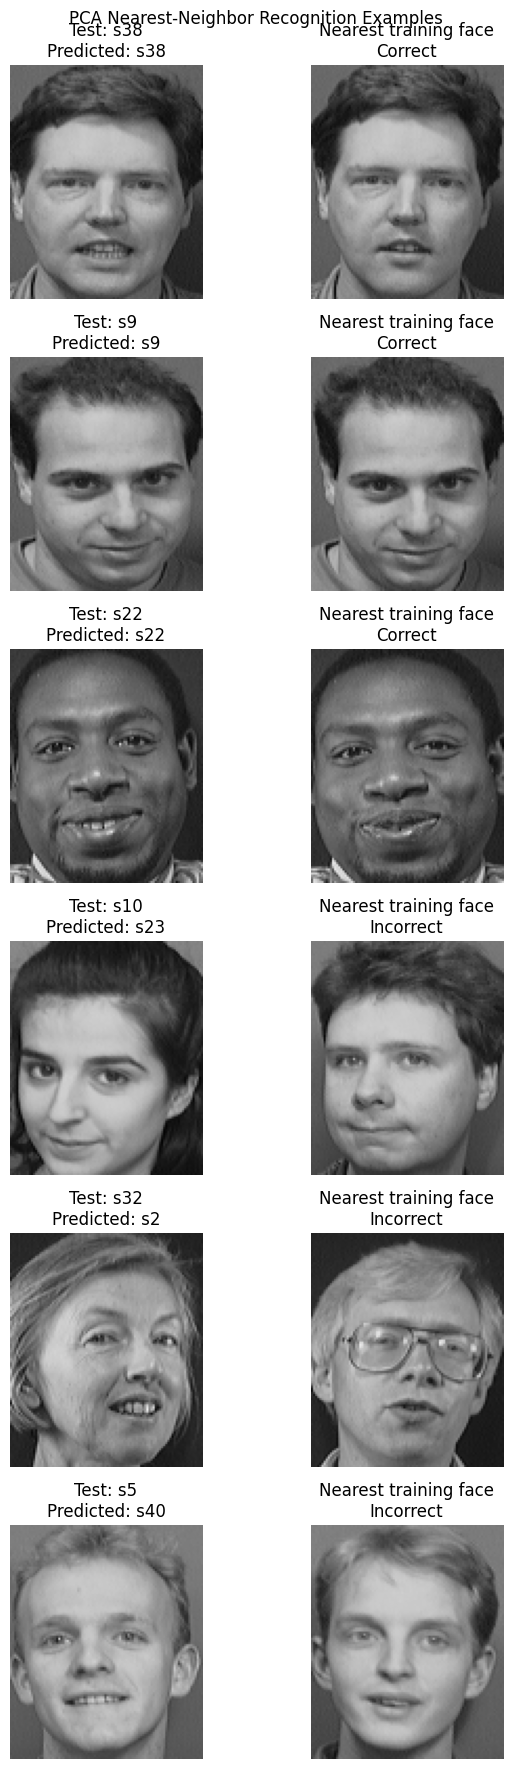

In [27]:
# ============================================================
# 26. VISUALIZE SELECTED PCA MATCHES
# ============================================================

orl_match_visualization_indices = []

# Include up to three correct predictions
orl_match_visualization_indices.extend(
    orl_pca_match_results.loc[
        orl_pca_match_results["Correct"],
        "Test_Index"
    ].head(3).tolist()
)

# Include up to three incorrect predictions
orl_match_visualization_indices.extend(
    orl_pca_match_results.loc[
        ~orl_pca_match_results["Correct"],
        "Test_Index"
    ].head(3).tolist()
)

if orl_match_visualization_indices:
    fig, axes = plt.subplots(
        len(orl_match_visualization_indices),
        2,
        figsize=(7, 3 * len(orl_match_visualization_indices)),
        squeeze=False
    )

    for row_index, test_index in enumerate(
        orl_match_visualization_indices
    ):
        nearest_train_index = orl_pca_nearest_indices[test_index]

        orl_test_face = orl_X_test_raw[test_index].reshape(
            orl_image_height, orl_image_width
        )

        orl_matched_train_face = orl_X_train_raw[
            nearest_train_index
        ].reshape(orl_image_height, orl_image_width)

        prediction_status = (
            "Correct"
            if orl_pca_correct_predictions[test_index]
            else "Incorrect"
        )

        axes[row_index, 0].imshow(
            orl_test_face, cmap="gray", vmin=0, vmax=255
        )
        axes[row_index, 0].set_title(
            f"Test: {orl_y_test[test_index]}\n"
            f"Predicted: {orl_pca_predicted_labels[test_index]}"
        )
        axes[row_index, 0].axis("off")

        axes[row_index, 1].imshow(
            orl_matched_train_face,
            cmap="gray",
            vmin=0,
            vmax=255
        )
        axes[row_index, 1].set_title(
            f"Nearest training face\n{prediction_status}"
        )
        axes[row_index, 1].axis("off")

    plt.suptitle("PCA Nearest-Neighbor Recognition Examples")
    plt.tight_layout()
    plt.show()
else:
    print("No test examples available for visualization.")

## Part D — Traditional Machine Learning

### D1. Classification Using PCA Features

We will train two traditional machine-learning classifiers using the PCA representations:

1. **K-Nearest Neighbors (KNN):** predicts a subject using the majority label among its nearest training examples.
2. **Support Vector Machine (SVM):** learns decision boundaries that separate the subject classes.

Both classifiers will use the same PCA representation and train-test split as the nearest-neighbor baseline. We will compare their test accuracies and computational representation sizes.

To avoid selecting model settings based on test-set performance, we will use stratified cross-validation on the training data for model selection. The test set will be reserved for final evaluation.

In [28]:
# ============================================================
# 27. IMPORT TRADITIONAL MACHINE-LEARNING CLASSIFIERS
# ============================================================

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

# Each subject has 7 training images, so 5-fold stratified
# cross-validation can retain examples of every subject per fold.
orl_cv_splitter = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_SEED
)

print("KNN and SVM imports completed successfully.")
print("Cross-validation folds:", orl_cv_splitter.get_n_splits())

KNN and SVM imports completed successfully.
Cross-validation folds: 5


In [29]:
# ============================================================
# 28. SELECT MODEL SETTINGS USING TRAINING CROSS-VALIDATION
# ============================================================

orl_candidate_models = {
    "KNN (k=1)": KNeighborsClassifier(n_neighbors=1),
    "KNN (k=3)": KNeighborsClassifier(n_neighbors=3),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "SVM (linear)": make_pipeline(
        StandardScaler(),
        SVC(kernel="linear", C=1.0)
    ),
    "SVM (RBF, C=1)": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=1.0, gamma="scale")
    ),
    "SVM (RBF, C=10)": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=10.0, gamma="scale")
    )
}

orl_model_selection_rows = []

for model_name, candidate_model in orl_candidate_models.items():
    orl_cv_scores = cross_val_score(
        candidate_model,
        orl_X_train_pca,
        orl_y_train,
        cv=orl_cv_splitter,
        scoring="accuracy",
        n_jobs=-1
    )

    orl_model_selection_rows.append({
        "Model": model_name,
        "Mean_CV_Accuracy": orl_cv_scores.mean(),
        "Std_CV_Accuracy": orl_cv_scores.std()
    })

orl_model_selection_table = pd.DataFrame(
    orl_model_selection_rows
).sort_values(
    by="Mean_CV_Accuracy",
    ascending=False
).reset_index(drop=True)

display(orl_model_selection_table.round(4))

,Model,Mean_CV_Accuracy,Std_CV_Accuracy
0,KNN (k=1),0.9500,0.0071
1,KNN (k=3),0.9071,0.0262
2,SVM (linear),0.8750,0.0196
3,"SVM (RBF, C=10)",0.8571,0.0196
4,KNN (k=5),0.8357,0.0286
5,"SVM (RBF, C=1)",0.8357,0.0208


In [30]:
# ============================================================
# 29. FIT THE SELECTED KNN AND SVM MODELS
# ============================================================

orl_best_knn_name = (
    orl_model_selection_table[
        orl_model_selection_table["Model"].str.startswith("KNN")
    ].iloc[0]["Model"]
)

orl_best_svm_name = (
    orl_model_selection_table[
        orl_model_selection_table["Model"].str.startswith("SVM")
    ].iloc[0]["Model"]
)

orl_selected_knn_model = clone(
    orl_candidate_models[orl_best_knn_name]
)

orl_selected_svm_model = clone(
    orl_candidate_models[orl_best_svm_name]
)

orl_selected_knn_model.fit(orl_X_train_pca, orl_y_train)
orl_selected_svm_model.fit(orl_X_train_pca, orl_y_train)

orl_knn_predicted_labels = orl_selected_knn_model.predict(
    orl_X_test_pca
)

orl_svm_predicted_labels = orl_selected_svm_model.predict(
    orl_X_test_pca
)

orl_knn_test_accuracy = np.mean(
    orl_knn_predicted_labels == orl_y_test
)

orl_svm_test_accuracy = np.mean(
    orl_svm_predicted_labels == orl_y_test
)

print("Selected KNN configuration:", orl_best_knn_name)
print(f"KNN test accuracy: {orl_knn_test_accuracy:.2%}")

print("\nSelected SVM configuration:", orl_best_svm_name)
print(f"SVM test accuracy: {orl_svm_test_accuracy:.2%}")

Selected KNN configuration: KNN (k=1)
KNN test accuracy: 97.50%

Selected SVM configuration: SVM (linear)
SVM test accuracy: 95.00%


### D2. Effect of Component Count on Recognition

Retaining more principal components generally preserves more information, but it also increases the size of the representation. Fewer components may provide a more compact representation, although recognition accuracy can decrease.

We will evaluate several component counts using cross-validation on the training data. The principal directions will remain fixed, and each candidate representation will use the first \(k\) directions.

We will then evaluate the selected component count on the test set. The test set will not be used to choose the component count or model settings.

In [31]:
# ============================================================
# 30. COMPARE COMPONENT COUNTS USING TRAINING CROSS-VALIDATION
# ============================================================

orl_component_candidates = [
    component_count
    for component_count in [10, 20, 40, 60, 92, 120, 160, 200]
    if component_count <= orl_eigenface_components.shape[1]
]

orl_component_experiment_rows = []

for component_count in orl_component_candidates:
    # Project training images using the first k principal directions
    orl_train_features_k = (
        orl_X_train_centered
        @ orl_eigenface_components[:, :component_count]
    )

    # Evaluate one KNN and one SVM configuration at each k
    orl_knn_cv_model = KNeighborsClassifier(n_neighbors=1)

    orl_svm_cv_model = make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=1.0, gamma="scale")
    )

    orl_knn_cv_scores_k = cross_val_score(
        orl_knn_cv_model,
        orl_train_features_k,
        orl_y_train,
        cv=orl_cv_splitter,
        scoring="accuracy",
        n_jobs=-1
    )

    orl_svm_cv_scores_k = cross_val_score(
        orl_svm_cv_model,
        orl_train_features_k,
        orl_y_train,
        cv=orl_cv_splitter,
        scoring="accuracy",
        n_jobs=-1
    )

    orl_component_experiment_rows.append({
        "Components": component_count,
        "KNN_CV_Accuracy": orl_knn_cv_scores_k.mean(),
        "SVM_CV_Accuracy": orl_svm_cv_scores_k.mean(),
        "KNN_CV_Std": orl_knn_cv_scores_k.std(),
        "SVM_CV_Std": orl_svm_cv_scores_k.std()
    })

orl_component_experiment_table = pd.DataFrame(
    orl_component_experiment_rows
)

display(orl_component_experiment_table.round(4))

,Components,KNN_CV_Accuracy,SVM_CV_Accuracy,KNN_CV_Std,SVM_CV_Std
0,10,0.9036,0.8857,0.0214,0.0242
1,20,0.9500,0.9393,0.0134,0.0242
2,40,0.9571,0.9429,0.0143,0.0175
3,60,0.9571,0.9036,0.0143,0.0242
4,92,0.9500,0.8357,0.0071,0.0208
5,120,0.9536,0.7250,0.0087,0.0432
6,160,0.9536,0.5643,0.0087,0.0214
7,200,0.9500,0.4357,0.0134,0.0350


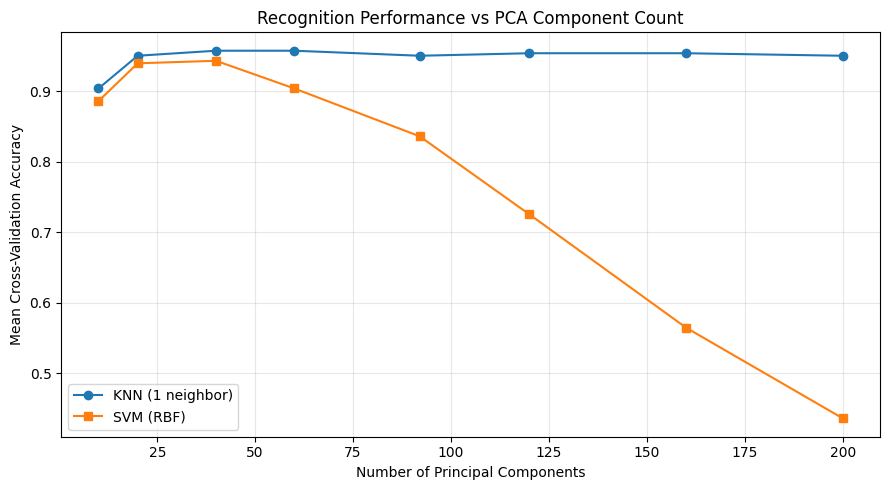

In [32]:
# ============================================================
# 31. PLOT CROSS-VALIDATION ACCURACY VS COMPONENT COUNT
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    orl_component_experiment_table["Components"],
    orl_component_experiment_table["KNN_CV_Accuracy"],
    marker="o",
    label="KNN (1 neighbor)"
)

plt.plot(
    orl_component_experiment_table["Components"],
    orl_component_experiment_table["SVM_CV_Accuracy"],
    marker="s",
    label="SVM (RBF)"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.title("Recognition Performance vs PCA Component Count")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [33]:
# ============================================================
# 32. FINAL TEST-SET COMPARISON
# ============================================================

orl_final_comparison_rows = [
    {
        "Method": "Nearest Neighbor — Raw Pixels",
        "Features": orl_X_train_raw.shape[1],
        "Test_Accuracy": orl_raw_recognition_accuracy
    },
    {
        "Method": "Nearest Neighbor — PCA",
        "Features": orl_X_train_pca.shape[1],
        "Test_Accuracy": orl_pca_recognition_accuracy
    },
    {
        "Method": f"{orl_best_knn_name} — PCA",
        "Features": orl_X_train_pca.shape[1],
        "Test_Accuracy": orl_knn_test_accuracy
    },
    {
        "Method": f"{orl_best_svm_name} — PCA",
        "Features": orl_X_train_pca.shape[1],
        "Test_Accuracy": orl_svm_test_accuracy
    }
]

orl_final_comparison_table = pd.DataFrame(
    orl_final_comparison_rows
)

orl_final_comparison_table["Accuracy_Percent"] = (
    orl_final_comparison_table["Test_Accuracy"] * 100
)

display(orl_final_comparison_table.round(2))

,Method,Features,Test_Accuracy,Accuracy_Percent
0,Nearest Neighbor — Raw Pixels,10304,0.98,97.5
1,Nearest Neighbor — PCA,92,0.98,97.5
2,KNN (k=1) — PCA,92,0.98,97.5
3,SVM (linear) — PCA,92,0.95,95.0


## Part E — Results and Discussion

### E1. Summary of Findings

The ORL face dataset contains 400 grayscale images from 40 subjects. Each image has dimensions \(112 \times 92\), producing 10,304 pixel features.

PCA was implemented using NumPy eigendecomposition and Singular Value Decomposition (SVD). Both methods produced matching eigenvalues and principal directions up to numerical precision.

The first 92 principal components preserve approximately 90.04% of the training variance. This reduces each image's representation from 10,304 pixel values to 92 PCA coefficients.

### E2. Reconstruction and Compression

The reconstructed test images preserve the overall facial structure but lose some fine details. With 92 components, the test reconstruction MSE is approximately 335.52, and the RMSE is approximately 18.32 intensity levels.

The PCA coefficients alone require 736 bytes per image when stored as 64-bit floating-point values, compared with 10,304 bytes for the original 8-bit pixel representation. However, the shared PCA model requires additional storage. For this relatively small dataset, storing the uncompressed PCA model and all coefficients together requires more space than the original pixel matrix.

### E3. Recognition Performance

On the selected train-test split, raw-pixel nearest-neighbor matching achieves 97.50% accuracy. Nearest-neighbor matching using PCA features achieves the same accuracy while using substantially fewer features.

The KNN classifier also achieves 97.50% test accuracy, while the selected linear SVM achieves 95.00%.

These results demonstrate that PCA can substantially reduce the dimensionality of face images while retaining useful information for recognition.

### E4. Effect of Component Count

The component-count experiment shows that recognition performance depends on both the representation size and the classifier. Retaining more principal components does not necessarily improve classification accuracy.

The best configuration should be selected using training-only cross-validation, with the held-out test set reserved for final evaluation.

### E5. Limitations

- The evaluation uses one train-test split of a relatively small dataset.
- Recognition performance may change with different splits, subjects, lighting conditions, and facial expressions.
- PCA maximizes variance preservation, not class separation.
- The PCA model's storage cost is substantial when measured against a small dataset.
- The results do not establish how the approach would perform on larger or more diverse face datasets.

### Conclusion

This project demonstrates a complete face-recognition workflow using numerical image representations, NumPy-based PCA, eigenfaces, reconstruction, nearest-neighbor matching, and traditional machine-learning classifiers. The results illustrate the trade-off between dimensionality reduction, reconstruction quality, storage requirements, and recognition accuracy.

## Part F — Exporting Results

We will save the key visualizations and numerical results into an `outputs` directory. These artifacts include the explained-variance plot, eigenfaces, reconstruction examples, recognition examples, and comparison tables.

The saved files can be referenced in the project README and included in the public GitHub repository.

In [34]:
# ============================================================
# 33. CREATE OUTPUT DIRECTORY
# ============================================================

OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR)

Output directory: c:\Users\pujit\Desktop\DAU\Sem 1\DS605 Fundamentals of Machine Learning\Lab\202618003_Pujita_Sunnapu_DS605\202618003_Lab7\outputs


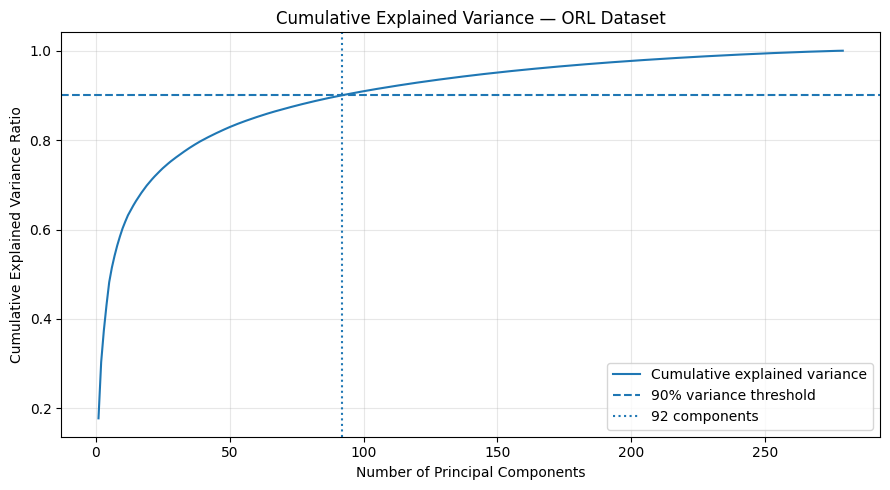

In [35]:
# ============================================================
# 34. SAVE CUMULATIVE EXPLAINED VARIANCE FIGURE
# ============================================================

orl_variance_figure, orl_variance_axis = plt.subplots(figsize=(9, 5))

orl_variance_axis.plot(
    np.arange(1, len(orl_cumulative_explained_variance) + 1),
    orl_cumulative_explained_variance,
    label="Cumulative explained variance"
)

orl_variance_axis.axhline(
    y=orl_variance_threshold,
    linestyle="--",
    label="90% variance threshold"
)

orl_variance_axis.axvline(
    x=orl_components_for_90_variance,
    linestyle=":",
    label=f"{orl_components_for_90_variance} components"
)

orl_variance_axis.set_xlabel("Number of Principal Components")
orl_variance_axis.set_ylabel("Cumulative Explained Variance Ratio")
orl_variance_axis.set_title("Cumulative Explained Variance — ORL Dataset")
orl_variance_axis.grid(alpha=0.3)
orl_variance_axis.legend()

orl_variance_figure.tight_layout()
orl_variance_figure.savefig(
    OUTPUT_DIR / "explained_variance.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

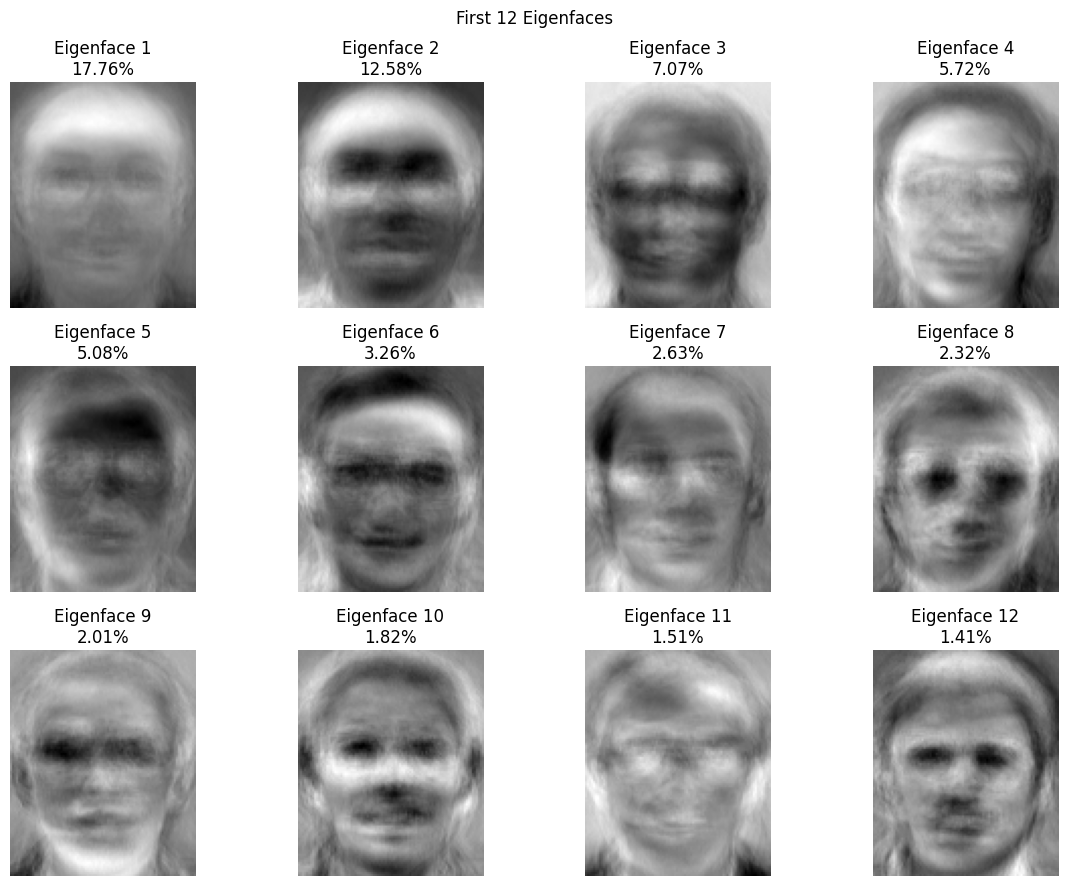

In [36]:
# ============================================================
# 35. SAVE EIGENFACE VISUALIZATION
# ============================================================

orl_saved_eigenface_figure, orl_saved_eigenface_axes = plt.subplots(
    3, 4, figsize=(12, 9)
)

for eigenface_index, axis in enumerate(
    orl_saved_eigenface_axes.flat
):
    eigenface_image = orl_eigenface_components[
        :, eigenface_index
    ].reshape(orl_image_height, orl_image_width)

    axis.imshow(eigenface_image, cmap="gray")
    axis.set_title(
        f"Eigenface {eigenface_index + 1}\n"
        f"{orl_explained_variance_ratio[eigenface_index]:.2%}"
    )
    axis.axis("off")

orl_saved_eigenface_figure.suptitle("First 12 Eigenfaces")
orl_saved_eigenface_figure.tight_layout()
orl_saved_eigenface_figure.savefig(
    OUTPUT_DIR / "eigenfaces.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

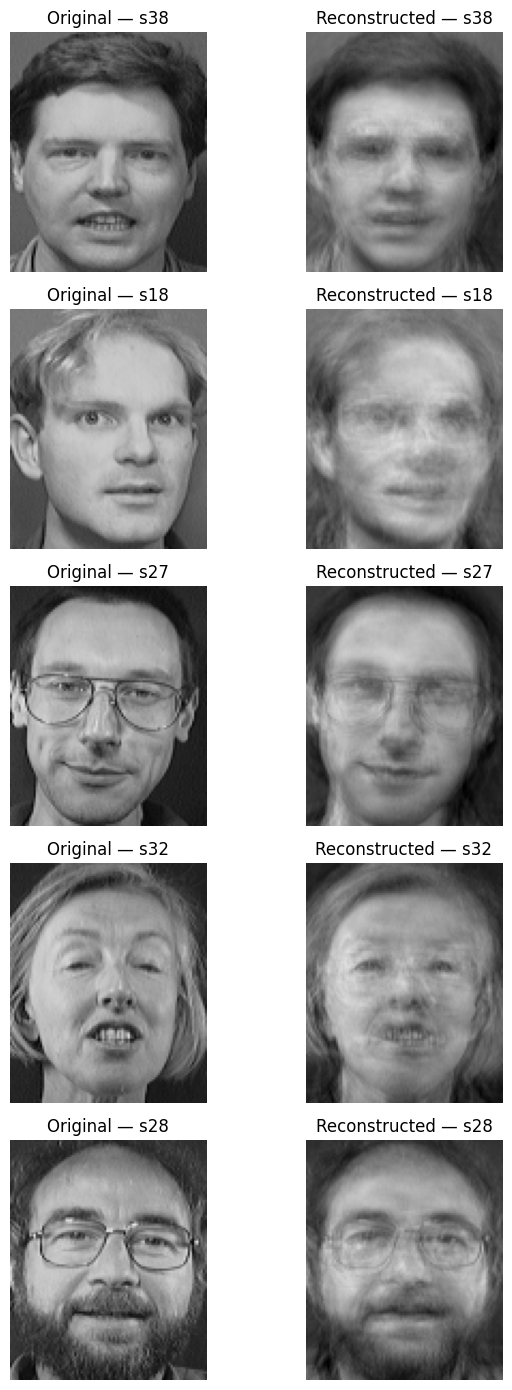

In [37]:
# ============================================================
# 36. SAVE RECONSTRUCTION COMPARISON FIGURE
# ============================================================

orl_saved_reconstruction_figure, orl_saved_reconstruction_axes = (
    plt.subplots(5, 2, figsize=(7, 14))
)

for row_index, test_index in enumerate(
    orl_reconstruction_sample_indices
):
    orl_original_face = orl_X_test_raw[test_index].reshape(
        orl_image_height, orl_image_width
    )

    orl_reconstructed_face = orl_X_test_reconstructed[
        test_index
    ].reshape(orl_image_height, orl_image_width)

    orl_saved_reconstruction_axes[row_index, 0].imshow(
        orl_original_face, cmap="gray", vmin=0, vmax=255
    )
    orl_saved_reconstruction_axes[row_index, 0].set_title(
        f"Original — {orl_y_test[test_index]}"
    )
    orl_saved_reconstruction_axes[row_index, 0].axis("off")

    orl_saved_reconstruction_axes[row_index, 1].imshow(
        orl_reconstructed_face,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    orl_saved_reconstruction_axes[row_index, 1].set_title(
        f"Reconstructed — {orl_y_test[test_index]}"
    )
    orl_saved_reconstruction_axes[row_index, 1].axis("off")

orl_saved_reconstruction_figure.tight_layout()
orl_saved_reconstruction_figure.savefig(
    OUTPUT_DIR / "reconstruction_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [38]:
# ============================================================
# 37. EXPORT RESULTS TABLES
# ============================================================

orl_variance_table.to_csv(
    OUTPUT_DIR / "explained_variance.csv",
    index=False
)

orl_eigenvalue_comparison.to_csv(
    OUTPUT_DIR / "eigendecomposition_vs_svd.csv",
    index=False
)

orl_storage_summary.to_csv(
    OUTPUT_DIR / "storage_comparison.csv",
    index=False
)

orl_recognition_comparison.to_csv(
    OUTPUT_DIR / "nearest_neighbor_comparison.csv",
    index=False
)

orl_model_selection_table.to_csv(
    OUTPUT_DIR / "classifier_cross_validation.csv",
    index=False
)

orl_component_experiment_table.to_csv(
    OUTPUT_DIR / "component_count_experiment.csv",
    index=False
)

orl_final_comparison_table.to_csv(
    OUTPUT_DIR / "final_recognition_comparison.csv",
    index=False
)

print("Results tables saved to:", OUTPUT_DIR)

for saved_file in sorted(OUTPUT_DIR.iterdir()):
    print(saved_file.name)

Results tables saved to: c:\Users\pujit\Desktop\DAU\Sem 1\DS605 Fundamentals of Machine Learning\Lab\202618003_Pujita_Sunnapu_DS605\202618003_Lab7\outputs
classifier_cross_validation.csv
component_count_experiment.csv
eigendecomposition_vs_svd.csv
eigenfaces.png
explained_variance.csv
explained_variance.png
final_recognition_comparison.csv
nearest_neighbor_comparison.csv
reconstruction_comparison.png
storage_comparison.csv


## Part G — Project Documentation

The README will describe the problem, dataset, methodology, implementation constraints, results, and instructions for running the notebook. It will also reference the figures and tables saved in the `outputs` directory.

In [39]:
# ============================================================
# 38. GENERATE PROJECT README
# ============================================================

orl_readme_content = f"""# Image Representation, PCA, Eigenfaces and Face Recognition

**Course:** DS605 — Fundamentals of Machine Learning  
**Assignment:** Lab Assignment 7

## Objective

Represent face images numerically, implement PCA using NumPy linear algebra,
visualize eigenfaces, reconstruct images, perform face recognition, and compare
similarity-based matching with traditional machine-learning classifiers.

## Dataset

This project uses the AT&T Database of Faces (ORL).

- Images loaded: {len(orl_image_arrays)}
- Subjects: {len(orl_unique_subjects)}
- Images per subject: 10
- Image dimensions: {orl_image_height} × {orl_image_width}
- Original pixel features per image: {orl_num_pixels}

Place the extracted dataset under `data/archive/`, with subject folders such
as `s1`, `s2`, and so on.

## Methodology

1. Load grayscale PGM images and extract subject labels.
2. Flatten images into pixel feature vectors.
3. Create a reproducible, subject-stratified train-test split.
4. Compute the mean face and center the data.
5. Implement covariance-based eigendecomposition using a smaller Gram matrix.
6. Implement PCA independently using NumPy SVD.
7. Compare eigenvalues and principal directions from both methods.
8. Select components using cumulative explained variance.
9. Visualize eigenfaces and reconstruct test images.
10. Compare raw-pixel and PCA-space nearest-neighbor recognition.
11. Train KNN and SVM classifiers on PCA features.
12. Compare component counts using training cross-validation.

PCA calculations use NumPy linear-algebra operations rather than
scikit-learn's PCA implementation.

## Train-Test Split

Each subject contributes 7 training images and 3 test images.

- Training images: {len(orl_y_train)}
- Test images: {len(orl_y_test)}
- Random seed: {RANDOM_SEED}

## PCA Results

- Components selected for at least 90% variance: {orl_components_for_90_variance}
- Cumulative explained variance: {orl_cumulative_explained_variance[orl_components_for_90_variance - 1]:.4%}
- Test reconstruction MSE: {orl_test_reconstruction_mse:.4f}
- Test reconstruction RMSE: {orl_test_reconstruction_rmse:.4f}

## Recognition Results

| Method | Features | Test Accuracy |
|---|---:|---:|
| Nearest Neighbor — Raw Pixels | {orl_X_train_raw.shape[1]} | {orl_raw_recognition_accuracy:.2%} |
| Nearest Neighbor — PCA | {orl_X_train_pca.shape[1]} | {orl_pca_recognition_accuracy:.2%} |
| {orl_best_knn_name} — PCA | {orl_X_train_pca.shape[1]} | {orl_knn_test_accuracy:.2%} |
| {orl_best_svm_name} — PCA | {orl_X_train_pca.shape[1]} | {orl_svm_test_accuracy:.2%} |

These results correspond to the specified random split and should not be
interpreted as a guarantee of performance on other datasets.

## Figures

- `outputs/explained_variance.png`
- `outputs/eigenfaces.png`
- `outputs/reconstruction_comparison.png`

## Results Tables

The `outputs/` directory also contains CSV files for explained variance,
eigendecomposition versus SVD, storage comparison, classifier cross-validation,
component-count experiments, and final recognition comparisons.

## Requirements

- Python 3
- NumPy
- Pandas
- Matplotlib
- Pillow
- scikit-learn
- Jupyter Notebook

## Run the Project

1. Clone or download this repository.
2. Install the required packages.
3. Place the extracted ORL dataset under `data/archive/`.
4. Open the notebook in Jupyter.
5. Run the cells from top to bottom.

## Limitations

PCA maximizes variance preservation rather than class separation. The dataset is
small, and results depend on the train-test split. The PCA model also requires
storage for the mean face and principal directions, which matters when evaluating
total storage on a small dataset.
"""

orl_readme_path = PROJECT_ROOT / "README.md"
orl_readme_path.write_text(orl_readme_content, encoding="utf-8")

print("README created:", orl_readme_path)
print("\nFirst 20 lines:\n")
print("\n".join(orl_readme_content.splitlines()[:20]))

README created: c:\Users\pujit\Desktop\DAU\Sem 1\DS605 Fundamentals of Machine Learning\Lab\202618003_Pujita_Sunnapu_DS605\202618003_Lab7\README.md

First 20 lines:

# Image Representation, PCA, Eigenfaces and Face Recognition

**Course:** DS605 — Fundamentals of Machine Learning  
**Assignment:** Lab Assignment 7

## Objective

Represent face images numerically, implement PCA using NumPy linear algebra,
visualize eigenfaces, reconstruct images, perform face recognition, and compare
similarity-based matching with traditional machine-learning classifiers.

## Dataset

This project uses the AT&T Database of Faces (ORL).

- Images loaded: 400
- Subjects: 40
- Images per subject: 10
- Image dimensions: 112 × 92
- Original pixel features per image: 10304


In [40]:
# ============================================================
# 39. FINAL PROJECT ARTIFACT CHECK
# ============================================================

orl_expected_artifacts = [
    OUTPUT_DIR / "explained_variance.png",
    OUTPUT_DIR / "eigenfaces.png",
    OUTPUT_DIR / "reconstruction_comparison.png",
    OUTPUT_DIR / "explained_variance.csv",
    OUTPUT_DIR / "eigendecomposition_vs_svd.csv",
    OUTPUT_DIR / "storage_comparison.csv",
    OUTPUT_DIR / "nearest_neighbor_comparison.csv",
    OUTPUT_DIR / "classifier_cross_validation.csv",
    OUTPUT_DIR / "component_count_experiment.csv",
    OUTPUT_DIR / "final_recognition_comparison.csv",
    orl_readme_path
]

orl_artifact_status = pd.DataFrame({
    "Artifact": [
        str(artifact.relative_to(PROJECT_ROOT))
        for artifact in orl_expected_artifacts
    ],
    "Exists": [
        artifact.exists()
        for artifact in orl_expected_artifacts
    ]
})

display(orl_artifact_status)

assert orl_artifact_status["Exists"].all(), (
    "Some project artifacts are missing. Check the preceding cells."
)

print("All expected artifacts were created successfully.")

,Artifact,Exists
0,outputs\explained_variance.png,True
1,outputs\eigenfaces.png,True
2,outputs\reconstruction_comparison.png,True
3,outputs\explained_variance.csv,True
4,outputs\eigendecomposition_vs_svd.csv,True
5,outputs\storage_comparison.csv,True
6,outputs\nearest_neighbor_comparison.csv,True
7,outputs\classifier_cross_validation.csv,True
8,outputs\component_count_experiment.csv,True
9,outputs\final_recognition_comparison.csv,True


All expected artifacts were created successfully.
